# Reach-U: Mobile Location Anomaly Detection

## Project objectives

1. Detect unrealistic location jumps in mobile network data.
2. Identify suspicious records in movement trajectories.
3. Analyse technical variables associated with anomalies.
4. Develop and evaluate simple filtering rules that do not require chronological sorting.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from geopy.distance import geodesic
from pathlib import Path

In [3]:
file_path = Path("anomalies_corrected_data.xlsx")

df = pd.read_excel(file_path, sheet_name="Data")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 15875
Columns: 18


,step,rat_id,eci_nci,network,timestamp,latitude,longitude,geometry_type,start_angle,end_angle,outer_radius,inner_radius,cell_updated_flag,device_interface_type,server,application_name,message_name,apn_name
0,1,23,16385048599,5G,2025-12-24T00:11:06.980908Z,48.171697,11.639356,ARC,180,300,1222,0,NaN,N1,W-AMF2,5GMM,5GMM-SRV-REQ,NaN
1,2,23,16385048599,5G,2025-12-24T00:11:06.981973Z,48.171697,11.639356,ARC,180,300,1222,0,0.0,N1,W-AMF2,NSMF,NsmfPDUSession_UpdateSMContext,NaN
2,3,23,16385048599,5G,2025-12-24T00:11:06.982002Z,48.171697,11.639356,ARC,180,300,1222,0,NaN,N11,W-N11,NSMF,NsmfPDUSession_UpdateSMContext,pda
3,4,23,16385048599,5G,2025-12-24T00:11:07.043218Z,48.171697,11.639356,ARC,180,300,1222,0,NaN,N1,W-AMF2,NG-AP,NGAPINIT_CTX_SETUP,NaN
4,5,23,16385048599,5G,2025-12-24T00:11:07.044096Z,48.171697,11.639356,ARC,180,300,1222,0,0.0,N1,W-AMF2,NSMF,NsmfPDUSession_UpdateSMContext,NaN


## 1. Exploratory Data Analysis (EDA)

First, we examine the dataset structure, variable types and missing values to understand the data before detecting anomalies.

In [4]:
# Display dataset structure
df.info()

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 15875 entries, 0 to 15874
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   step                   15875 non-null  int64  
 1   rat_id                 15875 non-null  int64  
 2   eci_nci                15875 non-null  int64  
 3   network                15875 non-null  str    
 4   timestamp              15875 non-null  str    
 5   latitude               15875 non-null  float64
 6   longitude              15875 non-null  float64
 7   geometry_type          15875 non-null  str    
 8   start_angle            15875 non-null  int64  
 9   end_angle              15875 non-null  int64  
 10  outer_radius           15875 non-null  int64  
 11  inner_radius           15875 non-null  int64  
 12  cell_updated_flag      9656 non-null   float64
 13  device_interface_type  15875 non-null  str    
 14  server                 15875 non-null  str    
 15  application_n

In [5]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_values / len(df)) * 100

# Create summary table
missing_summary = pd.DataFrame({
    "Missing count": missing_values,
    "Missing (%)": missing_percentage.round(2)
})

missing_summary

,Missing count,Missing (%)
step,0,0.00
rat_id,0,0.00
eci_nci,0,0.00
network,0,0.00
timestamp,0,0.00
latitude,0,0.00
longitude,0,0.00
geometry_type,0,0.00
start_angle,0,0.00
end_angle,0,0.00


## 2. Timestamp and Location Analysis

We examine timestamps and geographical coordinates to understand the movement data before detecting suspicious location jumps.

In [6]:
# Convert timestamps to datetime format
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

# Check the time range
print("First timestamp:", df["timestamp"].min())
print("Last timestamp:", df["timestamp"].max())

# Check if timestamps are sorted
print("Chronologically sorted:", df["timestamp"].is_monotonic_increasing)

# Count duplicate timestamps
print("Duplicate timestamps:", df["timestamp"].duplicated().sum())

First timestamp: 2025-12-24 00:11:06.980908+00:00
Last timestamp: 2025-12-29 00:42:11.226051+00:00
Chronologically sorted: True
Duplicate timestamps: 52


In [7]:
# Count unique coordinates and cell IDs
unique_locations = df[["latitude", "longitude"]].drop_duplicates()

print("Total records:", len(df))
print("Unique coordinates:", len(unique_locations))
print("Unique cell IDs:", df["eci_nci"].nunique())

# Coordinate ranges
df[["latitude", "longitude"]].describe()

Total records: 15875
Unique coordinates: 256
Unique cell IDs: 605


,latitude,longitude
count,15875.000000,15875.000000
mean,49.516906,15.477716
std,0.739375,2.246889
min,48.171600,11.618900
25%,48.763530,14.467814
50%,49.907258,15.957793
75%,50.006678,17.385122
max,50.070811,17.527619


## 3. Movement Trajectory Analysis

Consecutive observations with identical coordinates are grouped into location runs. This simplifies the trajectory and helps identify suspicious movement patterns such as A-B-A.

In [8]:
# Sort records chronologically without modifying the original dataset
df_sorted = df.sort_values(
    "timestamp", kind="stable"
).reset_index(drop=True).copy()

# Identify when the coordinates change
df_sorted["location_changed"] = (
    (df_sorted["latitude"] != df_sorted["latitude"].shift()) |
    (df_sorted["longitude"] != df_sorted["longitude"].shift())
)

# Assign a unique ID to each consecutive location run
df_sorted["run_id"] = df_sorted["location_changed"].cumsum()

# Group consecutive records with identical coordinates
runs = df_sorted.groupby("run_id").agg(
    start_step=("step", "first"),
    end_step=("step", "last"),
    start_time=("timestamp", "first"),
    end_time=("timestamp", "last"),
    latitude=("latitude", "first"),
    longitude=("longitude", "first"),
    n_records=("step", "size")
).reset_index()

print("Original records:", len(df))
print("Location runs:", len(runs))

runs.head(10)

Original records: 15875
Location runs: 1662


,run_id,start_step,end_step,start_time,end_time,latitude,longitude,n_records
0,1,1,705,2025-12-24 00:11:06.980908+00:00,2025-12-24 12:30:22.985613+00:00,48.171697,11.639356,705
1,2,706,706,2025-12-24 12:31:09.167096+00:00,2025-12-24 12:31:09.167096+00:00,48.182348,11.620717,1
2,3,707,717,2025-12-24 12:31:09.167147+00:00,2025-12-24 12:31:16.854702+00:00,48.171697,11.639356,11
3,4,718,720,2025-12-24 12:31:27.726969+00:00,2025-12-24 12:31:27.824033+00:00,48.182348,11.620717,3
4,5,721,721,2025-12-24 12:31:48.001915+00:00,2025-12-24 12:31:48.001915+00:00,48.171697,11.639356,1
5,6,722,722,2025-12-24 12:31:48.078407+00:00,2025-12-24 12:31:48.078407+00:00,48.182348,11.620717,1
6,7,723,726,2025-12-24 12:31:48.078448+00:00,2025-12-24 12:31:49.448381+00:00,48.171697,11.639356,4
7,8,727,727,2025-12-24 12:32:55.535239+00:00,2025-12-24 12:32:55.535239+00:00,48.181780,11.647270,1
8,9,728,728,2025-12-24 12:33:02.983210+00:00,2025-12-24 12:33:02.983210+00:00,48.172120,11.618900,1
9,10,729,729,2025-12-24 12:33:04.015199+00:00,2025-12-24 12:33:04.015199+00:00,48.181780,11.647270,1


In [9]:
# Previous location coordinates
runs["prev_lat"] = runs["latitude"].shift()
runs["prev_lon"] = runs["longitude"].shift()

# Calculate distance between consecutive locations (meters)
def calculate_distance(row):
    if pd.isna(row["prev_lat"]):
        return np.nan

    previous = (row["prev_lat"], row["prev_lon"])
    current = (row["latitude"], row["longitude"])

    return geodesic(previous, current).meters

runs["distance_m"] = runs.apply(calculate_distance, axis=1)

# Time between the end of the previous run and start of current run
runs["time_gap_s"] = (
    runs["start_time"] - runs["end_time"].shift()
).dt.total_seconds()

# Approximate speed in km/h (only when time difference is positive)
runs["speed_kmh"] = np.where(
    runs["time_gap_s"] > 0,
    runs["distance_m"] / runs["time_gap_s"].replace(0, np.nan) * 3.6,
    np.nan
)

runs[[
    "run_id", "start_step", "end_step",
    "distance_m", "time_gap_s", "speed_kmh"
]].head(10)

,run_id,start_step,end_step,distance_m,time_gap_s,speed_kmh
0,1,1,705,NaN,NaN,NaN
1,2,706,706,1823.214545,46.181483,1.421256e+02
2,3,707,717,1823.214545,0.000051,1.286975e+08
3,4,718,720,1823.214545,10.872267,6.036986e+02
4,5,721,721,1823.214545,20.177882,3.252855e+02
5,6,722,722,1823.214545,0.076492,8.580730e+04
6,7,723,726,1823.214545,0.000041,1.600871e+08
7,8,727,727,1266.263604,66.086858,6.897815e+01
8,9,728,728,2367.554817,7.447971,1.144365e+03
9,10,729,729,2367.554817,1.031989,8.259000e+03


## 4. Anomaly Detection

### 4.1. A-B-A Pattern Detection

We identify cases where the location changes from A to B and returns to A within a short time.

A suspicious excursion may indicate an incorrect mobile network location estimate.

In [10]:
# Get the next location coordinates
runs["next_lat"] = runs["latitude"].shift(-1)
runs["next_lon"] = runs["longitude"].shift(-1)

# Calculate the time from leaving A until returning to A
runs["return_time_s"] = (
    runs["start_time"].shift(-1) -
    runs["end_time"].shift(1)
).dt.total_seconds()

# Detect possible A-B-A patterns
runs["aba_candidate"] = (
    (runs["prev_lat"] == runs["next_lat"]) &
    (runs["prev_lon"] == runs["next_lon"]) &
    (runs["distance_m"] >= 1000) &
    (runs["return_time_s"].between(0, 600))
)

# Extract suspicious location runs
aba_candidates = runs[runs["aba_candidate"]].copy()

print("A-B-A candidates found:", len(aba_candidates))

aba_candidates[[
    "run_id",
    "start_step",
    "end_step",
    "distance_m",
    "return_time_s",
    "n_records"
]].head(15)

A-B-A candidates found: 660


,run_id,start_step,end_step,distance_m,return_time_s,n_records
1,2,706,706,1823.214545,46.181534,1
2,3,707,717,1823.214545,18.559873,11
3,4,718,720,1823.214545,31.147213,3
4,5,721,721,1823.214545,20.254374,1
5,6,722,722,1823.214545,0.076533,1
8,9,728,728,2367.554817,8.479960,1
10,11,730,730,1266.263604,17.679822,1
14,15,740,740,1939.271355,0.468349,1
18,19,765,765,1039.587024,0.001252,1
19,20,766,767,1039.587024,0.086236,2


### 4.2. Classification of A-B-A Candidates

We distinguish isolated A-B-A candidates from consecutive patterns that may indicate repeated switching between mobile network cells.

In [11]:
# Check whether neighboring runs are also A-B-A candidates
runs["previous_aba"] = runs["aba_candidate"].shift(
    1, fill_value=False
)

runs["next_aba"] = runs["aba_candidate"].shift(
    -1, fill_value=False
)

# Classify candidates
runs["aba_type"] = np.select(
    [
        runs["aba_candidate"] &
        (runs["previous_aba"] | runs["next_aba"]),

        runs["aba_candidate"]
    ],
    [
        "repeated_switching",
        "isolated_candidate"
    ],
    default="not_candidate"
)

# Display counts
print(runs["aba_type"].value_counts())

# Display isolated candidates
isolated_candidates = runs[
    runs["aba_type"] == "isolated_candidate"
]

isolated_candidates[[
    "run_id",
    "start_step",
    "end_step",
    "distance_m",
    "return_time_s",
    "n_records"
]].head(15)

aba_type
not_candidate         1002
repeated_switching     524
isolated_candidate     136
Name: count, dtype: int64


,run_id,start_step,end_step,distance_m,return_time_s,n_records
8,9,728,728,2367.554817,8.479960,1
10,11,730,730,1266.263604,17.679822,1
14,15,740,740,1939.271355,0.468349,1
32,33,799,799,1039.587024,3.031433,1
34,35,802,802,2540.876320,4.243990,1
36,37,805,805,1039.587024,7.441245,1
38,39,808,808,2540.876320,5.151239,1
41,42,813,815,1555.452418,8.710912,3
48,49,831,831,1469.984877,108.389251,1
50,51,834,834,1007.972990,0.240313,1


### 4.3. Investigation of Suspicious Location Jumps

We investigate individual anomaly candidates by examining their neighboring locations, timestamps and technical attributes.

In [12]:
# Select a suspicious location run
selected_run = 92

# Display previous, current and next location runs
context = runs[
    runs["run_id"].between(selected_run - 1, selected_run + 1)
]

display(context[[
    "run_id",
    "start_step",
    "end_step",
    "start_time",
    "end_time",
    "latitude",
    "longitude",
    "distance_m",
    "return_time_s",
    "aba_type"
]])

,run_id,start_step,end_step,start_time,end_time,latitude,longitude,distance_m,return_time_s,aba_type
90,91,1008,1013,2025-12-24 13:02:31.001075+00:00,2025-12-24 13:02:43.954827+00:00,48.319953,11.89619,2437.346662,39.820715,not_candidate
91,92,1014,1014,2025-12-24 13:02:43.954923+00:00,2025-12-24 13:02:43.954923+00:00,48.186344,11.62520,25013.571292,0.000121,isolated_candidate
92,93,1015,1035,2025-12-24 13:02:43.954948+00:00,2025-12-24 13:03:56.398063+00:00,48.319953,11.89619,25013.571292,160.167486,not_candidate


In [13]:
# Technical attributes to investigate
technical_columns = [
    "step",
    "run_id",
    "timestamp",
    "rat_id",
    "server",
    "message_name",
    "device_interface_type",
    "eci_nci"
]

# Keep only columns that exist in the dataset
available_columns = [
    col for col in technical_columns
    if col in df_sorted.columns
]

# Select records belonging to the three location runs
technical_data = df_sorted[
    df_sorted["run_id"].between(selected_run - 1, selected_run + 1)
]

# Display up to 3 records from each run
display(
    technical_data.groupby("run_id")
    .head(3)[available_columns]
)

,step,run_id,timestamp,rat_id,server,message_name,device_interface_type,eci_nci
1007,1008,91,2025-12-24 13:02:31.001075+00:00,23,W-N11,NsmfPDUSession_UpdateSMContext,N11,16385458219
1008,1009,91,2025-12-24 13:02:31.001098+00:00,23,W-AMF2,NsmfPDUSession_UpdateSMContext,N1,16385458219
1009,1010,91,2025-12-24 13:02:31.110225+00:00,23,W-AMF2,NGAPPATH_SWITCH,N1,16385458219
1013,1014,92,2025-12-24 13:02:43.954923+00:00,23,W-N11,NsmfPDUSession_RetrieveSMContext,N11,16385064982
1014,1015,93,2025-12-24 13:02:43.954948+00:00,23,W-AMF2,NsmfPDUSession_RetrieveSMContext,N1,16385458219
1015,1016,93,2025-12-24 13:02:45.448210+00:00,23,W-AMF2,NGAPUE_CXT_REL,N1,16385458219
1016,1017,93,2025-12-24 13:03:39.960167+00:00,23,W-AMF2,5GMM-REG-MOBILITY,N1,16385458247


### 4.4. Location Uncertainty Analysis

We investigate whether the dataset contains information about location accuracy, uncertainty or cell coverage radius.

This information can help distinguish unrealistic movement from normal switching between overlapping cell coverage areas.

In [14]:
# Find columns related to location uncertainty
keywords = [
    "radius",
    "accuracy",
    "uncertainty",
    "confidence",
    "range"
]

location_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in keywords)
]

print("Location uncertainty columns:")
print(location_columns)

# Display values for the suspicious location
if location_columns:
    display(
        df_sorted.loc[
            df_sorted["run_id"].between(91, 93),
            ["step", "run_id", "latitude", "longitude"]
            + location_columns
        ].head(15)
    )
else:
    print("No obvious uncertainty columns found.")

Location uncertainty columns:
['outer_radius', 'inner_radius']


,step,run_id,latitude,longitude,outer_radius,inner_radius
1007,1008,91,48.319953,11.89619,4057,0
1008,1009,91,48.319953,11.89619,4057,0
1009,1010,91,48.319953,11.89619,4057,0
1010,1011,91,48.319953,11.89619,2053,0
1011,1012,91,48.319953,11.89619,4057,0
1012,1013,91,48.319953,11.89619,4057,0
1013,1014,92,48.186344,11.62520,1758,0
1014,1015,93,48.319953,11.89619,4057,0
1015,1016,93,48.319953,11.89619,4057,0
1016,1017,93,48.319953,11.89619,2370,0


### 4.5. Radius-Based A-B-A Anomaly Detection

We improve the A-B-A detection method by considering the
outer radius of each location estimate.

The minimum distance between two location regions is:

d_min = max(0, distance - radius_A - radius_B)

We identify A-B-A patterns where the estimated location
regions do not overlap.

In [15]:
# Convert radius values to numeric format
df_sorted["outer_radius"] = pd.to_numeric(
    df_sorted["outer_radius"], errors="coerce"
)

# Use the maximum radius within each location run
radius_by_run = df_sorted.groupby("run_id")["outer_radius"].max()

runs["radius_m"] = runs["run_id"].map(radius_by_run)

# Previous and next location radii
runs["prev_radius_m"] = runs["radius_m"].shift(1)
runs["next_radius_m"] = runs["radius_m"].shift(-1)

# Minimum distance between previous and current location regions
runs["min_gap_in_m"] = (
    runs["distance_m"]
    - runs["prev_radius_m"]
    - runs["radius_m"]
).clip(lower=0)

# Distance from current location to next location
runs["next_distance_m"] = runs["distance_m"].shift(-1)

# Minimum distance between current and next location regions
runs["min_gap_out_m"] = (
    runs["next_distance_m"]
    - runs["radius_m"]
    - runs["next_radius_m"]
).clip(lower=0)

# A-B-A candidates with non-overlapping location regions
runs["aba_nonoverlapping"] = (
    runs["aba_candidate"]
    & (runs["min_gap_in_m"] > 0)
    & (runs["min_gap_out_m"] > 0)
)

# Compare results
print("Original A-B-A candidates:", runs["aba_candidate"].sum())
print("Non-overlapping A-B-A candidates:", runs["aba_nonoverlapping"].sum())

# Display candidates
radius_candidates = runs[runs["aba_nonoverlapping"]].copy()

display(radius_candidates[[
    "run_id",
    "start_step",
    "end_step",
    "distance_m",
    "min_gap_in_m",
    "min_gap_out_m",
    "return_time_s"
]].head(15).round(2))

Original A-B-A candidates: 660
Non-overlapping A-B-A candidates: 105


,run_id,start_step,end_step,distance_m,min_gap_in_m,min_gap_out_m,return_time_s
34,35,802,802,2540.88,567.88,567.88,4.24
38,39,808,808,2540.88,567.88,567.88,5.15
91,92,1014,1014,25013.57,19198.57,19198.57,0.00
175,176,1266,1266,10805.07,1088.07,1088.07,0.00
177,178,1285,1285,25618.24,15180.24,15180.24,5.15
178,179,1286,1286,25618.24,15180.24,15180.24,0.59
189,190,1345,1345,27603.26,16082.26,16082.26,0.41
194,195,1379,1379,28480.88,15332.88,15332.88,0.79
200,201,1442,1442,34295.93,25721.93,25721.93,0.62
202,203,1484,1484,19555.89,7785.89,7785.89,8.71


In [16]:
# Inspect the previously identified suspicious run
display(
    runs.loc[
        runs["run_id"] == 92,
        [
            "run_id",
            "distance_m",
            "radius_m",
            "prev_radius_m",
            "next_radius_m",
            "min_gap_in_m",
            "min_gap_out_m",
            "return_time_s",
            "aba_nonoverlapping"
        ]
    ].round(2)
)

,run_id,distance_m,radius_m,prev_radius_m,next_radius_m,min_gap_in_m,min_gap_out_m,return_time_s,aba_nonoverlapping
91,92,25013.57,1758,4057.0,4057.0,19198.57,19198.57,0.0,True


### 4.6. A1-B-A2 Pattern Detection

We extend anomaly detection to cases where the previous
and next locations are close but not identical.

A candidate is identified when:
1. A1 and A2 have overlapping location regions.
2. Their centers are at most 5 km apart.
3. B has no overlap with either A1 or A2.
4. The complete excursion occurs within 10 minutes.

In [17]:
# Calculate distance between previous and next locations
def calculate_anchor_distance(row):
    coords = [
        row["prev_lat"], row["prev_lon"],
        row["next_lat"], row["next_lon"]
    ]

    if any(pd.isna(value) for value in coords):
        return np.nan

    previous = (row["prev_lat"], row["prev_lon"])
    following = (row["next_lat"], row["next_lon"])

    return geodesic(previous, following).meters


runs["anchor_distance_m"] = runs.apply(
    calculate_anchor_distance, axis=1
)

# Minimum gap between A1 and A2 regions
runs["anchor_gap_m"] = (
    runs["anchor_distance_m"]
    - runs["prev_radius_m"]
    - runs["next_radius_m"]
).clip(lower=0)

# Identify A1-B-A2 candidates
runs["a1_b_a2_candidate"] = (
    (runs["anchor_distance_m"] <= 5000) &
    (runs["anchor_gap_m"] == 0) &
    (runs["min_gap_in_m"] > 0) &
    (runs["min_gap_out_m"] > 0) &
    (runs["return_time_s"].between(0, 600))
)

# Identify only newly detected candidates
runs["new_candidates"] = (
    runs["a1_b_a2_candidate"] &
    ~runs["aba_nonoverlapping"]
)

print(
    "Original radius-based A-B-A:",
    runs["aba_nonoverlapping"].sum()
)

print(
    "All A1-B-A2 candidates:",
    runs["a1_b_a2_candidate"].sum()
)

print(
    "New candidates:",
    runs["new_candidates"].sum()
)

# Display newly detected candidates
display(
    runs.loc[
        runs["new_candidates"],
        [
            "run_id",
            "start_step",
            "end_step",
            "anchor_distance_m",
            "min_gap_in_m",
            "min_gap_out_m",
            "return_time_s"
        ]
    ].head(15).round(3)
)

Original radius-based A-B-A: 105
All A1-B-A2 candidates: 125
New candidates: 20


,run_id,start_step,end_step,anchor_distance_m,min_gap_in_m,min_gap_out_m,return_time_s
348,349,2230,2232,681.016,3955.555,4008.914,4.716
350,351,2234,2236,681.016,4008.914,3564.555,3.702
450,451,4174,4177,1229.976,2985.667,1924.522,2.312
646,647,4749,4755,3134.885,2177.954,4298.872,8.222
681,682,4919,4919,563.741,6517.589,6074.036,0.056
683,684,4921,4927,563.741,6074.036,6517.589,26.684
752,753,6419,6429,0.000,578.064,578.064,22.296
753,754,6430,6430,0.000,578.064,578.064,0.000
755,756,6492,6492,0.000,496.112,496.112,15.898
756,757,6493,6493,0.000,496.112,496.112,0.324


### 4.7. Classification of Detected Anomaly Candidates

We classify the radius-based candidates into exact-return
and nearby-return patterns.

We also identify candidates that were missed by the
original distance threshold of 1000 meters.

In [18]:
# Identify exact returns (A-B-A)
runs["exact_return"] = (
    runs["a1_b_a2_candidate"] &
    np.isclose(runs["anchor_distance_m"], 0, atol=0.01)
)

# Identify nearby returns (A1-B-A2)
runs["near_return"] = (
    runs["a1_b_a2_candidate"] &
    (runs["anchor_distance_m"] > 0.01)
)

# Exact returns missed by the original 1000 m threshold
runs["new_exact_return"] = (
    runs["exact_return"] &
    ~runs["aba_nonoverlapping"]
)

# Genuinely new nearby-return patterns
runs["new_near_return"] = (
    runs["near_return"] &
    ~runs["aba_nonoverlapping"]
)

# Summary
summary = pd.Series({
    "Original radius-based A-B-A": runs["aba_nonoverlapping"].sum(),
    "Additional exact A-B-A": runs["new_exact_return"].sum(),
    "New A1-B-A2 patterns": runs["new_near_return"].sum(),
    "Total candidates": runs["a1_b_a2_candidate"].sum()
})

display(summary)

Original radius-based A-B-A    105
Additional exact A-B-A          10
New A1-B-A2 patterns            10
Total candidates               125
dtype: int64

## 5. Technical Attribute Analysis

### 5.1. Mapping Anomaly Candidates to Original Records

We map detected anomaly runs back to the original dataset.

This allows us to compare the technical attributes of
suspicious records with those of other records.

Candidate labels are preliminary and do not represent
manually confirmed anomalies.

In [19]:
# Get IDs of detected anomaly runs
candidate_run_ids = runs.loc[
    runs["a1_b_a2_candidate"], "run_id"
]

# Create a separate dataset for analysis
df_analysis = df_sorted.copy()

# Mark all records belonging to candidate runs
df_analysis["anomaly_candidate"] = (
    df_analysis["run_id"].isin(candidate_run_ids)
)

# Count candidate and other records
candidate_count = df_analysis["anomaly_candidate"].sum()
normal_count = (~df_analysis["anomaly_candidate"]).sum()

print("Total records:", len(df_analysis))
print("Candidate records:", candidate_count)
print("Other records:", normal_count)

print(
    "Candidate percentage:",
    round(candidate_count / len(df_analysis) * 100, 2),
    "%"
)

# Display sample candidate records
display(
    df_analysis.loc[
        df_analysis["anomaly_candidate"],
        [
            "step",
            "run_id",
            "timestamp",
            "server",
            "rat_id",
            "message_name",
            "device_interface_type"
        ]
    ].head(15)
)

Total records: 15875
Candidate records: 199
Other records: 15676
Candidate percentage: 1.25 %


,step,run_id,timestamp,server,rat_id,message_name,device_interface_type
801,802,35,2025-12-24 12:45:24.686706+00:00,W-N11,23,NsmfPDUSession_UpdateSMContext,N11
807,808,39,2025-12-24 12:45:37.476384+00:00,W-N11,23,NsmfPDUSession_UpdateSMContext,N11
1013,1014,92,2025-12-24 13:02:43.954923+00:00,W-N11,23,NsmfPDUSession_RetrieveSMContext,N11
1265,1266,176,2025-12-24 13:23:24.033577+00:00,W-N11,23,NsmfPDUSession_RetrieveSMContext,N11
1284,1285,178,2025-12-24 13:34:19.265361+00:00,W-AMF2,23,5GMM-REG-MOBILITY,N1
1285,1286,179,2025-12-24 13:34:19.278735+00:00,W-AMF2,23,5GMM-SEC-MODE-CNTRL,N1
1344,1345,190,2025-12-24 13:57:32.052852+00:00,W-AMF2,23,5GMM-SEC-MODE-CNTRL,N1
1378,1379,195,2025-12-24 14:19:04.710393+00:00,W-AMF2,23,5GMM-SEC-MODE-CNTRL,N1
1441,1442,201,2025-12-24 14:39:51.438710+00:00,W-AMF2,23,5GMM-SEC-MODE-CNTRL,N1
1483,1484,203,2025-12-24 14:50:21.333501+00:00,F-AMF2,23,5GMM-REG-MOBILITY,N1


### 5.2. Server-Based Anomaly Analysis

We investigate whether certain servers are associated with a higher proportion of suspicious location records.

For each server, we calculate:
- Total number of records
- Number of anomaly candidates
- Percentage of anomaly candidates
- Share of all detected candidates

These are preliminary candidate statistics, not confirmed error rates.

In [20]:
# Group records by server
server_analysis = df_analysis.groupby(
    "server", dropna=False
).agg(
    total_records=("anomaly_candidate", "size"),
    candidate_records=("anomaly_candidate", "sum")
)

# Calculate the candidate percentage for each server
server_analysis["candidate_rate"] = (
    server_analysis["candidate_records"] /
    server_analysis["total_records"] * 100
)

# Calculate the share of all detected candidates
server_analysis["candidate_share"] = (
    server_analysis["candidate_records"] /
    candidate_count * 100
)

# Sort servers by candidate rate
server_analysis = server_analysis.sort_values(
    "candidate_rate", ascending=False
)

display(server_analysis.round(2))

,total_records,candidate_records,candidate_rate,candidate_share
server,,,,
E-AMF1,219,9,4.11,4.52
E-MME,190,5,2.63,2.51
Z-AMF1,1034,20,1.93,10.05
Z-N11,1100,19,1.73,9.55
F-N11,3146,43,1.37,21.61
F-AMF2,8120,91,1.12,45.73
F-MME,196,2,1.02,1.01
W-N11,459,4,0.87,2.01
W-AMF2,1036,6,0.58,3.02


### 5.3. Visualization of Server Candidate Rates

We visualize the percentage of anomaly candidates for
each server to identify possible associations between
technical attributes and suspicious location estimates.

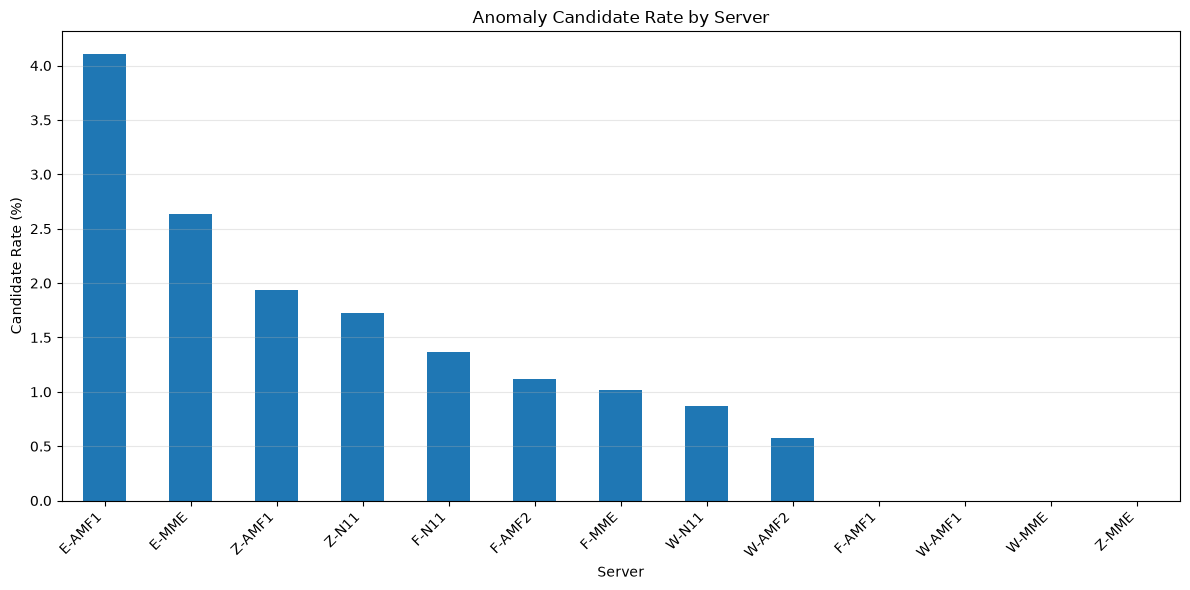

In [21]:
# Visualize anomaly candidate rates by server
plt.figure(figsize=(12, 6))

server_analysis["candidate_rate"].plot(
    kind="bar"
)

plt.title("Anomaly Candidate Rate by Server")
plt.xlabel("Server")
plt.ylabel("Candidate Rate (%)")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 5.4. Message Type Analysis

We investigate whether specific network message types
are associated with suspicious location records.

We compare candidate rates, candidate counts and
relative risk against the overall dataset.

In [22]:
# Overall candidate rate
overall_rate = df_analysis["anomaly_candidate"].mean() * 100

# Group by message type
message_analysis = df_analysis.groupby(
    "message_name", dropna=False
).agg(
    total_records=("anomaly_candidate", "size"),
    candidate_records=("anomaly_candidate", "sum")
)

# Candidate rate within each message type
message_analysis["candidate_rate"] = (
    message_analysis["candidate_records"] /
    message_analysis["total_records"] * 100
)

# Percentage of all candidates captured
message_analysis["candidate_share"] = (
    message_analysis["candidate_records"] /
    candidate_count * 100
)

# Relative candidate rate compared to the dataset average
message_analysis["lift"] = (
    message_analysis["candidate_rate"] / overall_rate
)

# Show message types with at least 30 records
message_analysis = message_analysis[
    message_analysis["total_records"] >= 30
].sort_values(
    "candidate_records", ascending=False
)

display(message_analysis.round(2))

,total_records,candidate_records,candidate_rate,candidate_share,lift
message_name,,,,,
NsmfPDUSession_UpdateSMContext,7539,80,1.06,40.20,0.85
NsmfPDUSession_RetrieveSMContext,826,27,3.27,13.57,2.61
5GMM-SEC-MODE-CNTRL,197,19,9.64,9.55,7.69
5GMM-REG-MOBILITY,373,18,4.83,9.05,3.85
NGAPUE_CXT_REL,1017,8,0.79,4.02,0.63
NsmfPDUSession_CreateSMContext,811,7,0.86,3.52,0.69
NGAPINIT_CTX_SETUP,945,6,0.63,3.02,0.51
NGAPUE_CXT_MOD,436,5,1.15,2.51,0.91
EMM-TAU-INTER-DCNR,107,4,3.74,2.01,2.98


### 5.5. Server and Message Type Combinations

We investigate whether combinations of server and message
type are more strongly associated with anomaly candidates
than individual technical attributes.

We compare candidate rates, candidate coverage,
dataset share and lift.

In [23]:
# Group records by server and message type
combination_analysis = df_analysis.groupby(
    ["server", "message_name"], dropna=False
).agg(
    total_records=("anomaly_candidate", "size"),
    candidate_records=("anomaly_candidate", "sum")
).reset_index()

# Candidate percentage within each combination
combination_analysis["candidate_rate"] = (
    combination_analysis["candidate_records"] /
    combination_analysis["total_records"] * 100
)

# Share of all detected candidates
combination_analysis["candidate_share"] = (
    combination_analysis["candidate_records"] /
    candidate_count * 100
)

# Share of the entire dataset
combination_analysis["dataset_share"] = (
    combination_analysis["total_records"] /
    len(df_analysis) * 100
)

# Relative candidate rate
combination_analysis["lift"] = (
    combination_analysis["candidate_rate"] / overall_rate
)

# Keep combinations with at least 30 records
filtered_combinations = combination_analysis[
    combination_analysis["total_records"] >= 30
].copy()

# Combinations with the most candidates
print("TOP 15 combinations by candidate count:")

display(
    filtered_combinations.sort_values(
        "candidate_records", ascending=False
    ).head(15).round(2)
)

# Combinations with the highest candidate percentage
print("TOP 15 combinations by candidate rate:")

display(
    filtered_combinations.sort_values(
        "candidate_rate", ascending=False
    ).head(15).round(2)
)

TOP 15 combinations by candidate count:


,server,message_name,total_records,candidate_records,candidate_rate,candidate_share,dataset_share,lift
67,F-N11,NsmfPDUSession_UpdateSMContext,2416,26,1.08,13.07,15.22,0.86
108,Z-AMF1,NsmfPDUSession_UpdateSMContext,976,18,1.84,9.05,6.15,1.47
40,F-AMF2,5GMM-REG-MOBILITY,348,17,4.89,8.54,2.19,3.90
118,Z-N11,NsmfPDUSession_UpdateSMContext,1042,17,1.63,8.54,6.56,1.30
59,F-AMF2,NsmfPDUSession_UpdateSMContext,2259,17,0.75,8.54,14.23,0.60
66,F-N11,NsmfPDUSession_RetrieveSMContext,361,15,4.16,7.54,2.27,3.31
41,F-AMF2,5GMM-SEC-MODE-CNTRL,185,14,7.57,7.04,1.17,6.04
58,F-AMF2,NsmfPDUSession_RetrieveSMContext,369,10,2.71,5.03,2.32,2.16
54,F-AMF2,NGAPUE_CXT_REL,895,8,0.89,4.02,5.64,0.71
50,F-AMF2,NGAPINIT_CTX_SETUP,829,6,0.72,3.02,5.22,0.58


TOP 15 combinations by candidate rate:


,server,message_name,total_records,candidate_records,candidate_rate,candidate_share,dataset_share,lift
41,F-AMF2,5GMM-SEC-MODE-CNTRL,185,14,7.57,7.04,1.17,6.04
105,Z-AMF1,NsmfPDUSession_CreateSMContext,30,2,6.67,1.01,0.19,5.32
115,Z-N11,NsmfPDUSession_CreateSMContext,30,2,6.67,1.01,0.19,5.32
16,E-MME,S1-AP-HO-PATH_SWITCH,47,3,6.38,1.51,0.30,5.09
11,E-MME,EMM-TAU-INTRA-DCNR,36,2,5.56,1.01,0.23,4.43
40,F-AMF2,5GMM-REG-MOBILITY,348,17,4.89,8.54,2.19,3.90
66,F-N11,NsmfPDUSession_RetrieveSMContext,361,15,4.16,7.54,2.27,3.31
47,F-AMF2,EMM-TAU-INTER-DCNR,61,2,3.28,1.01,0.38,2.62
3,E-AMF1,EMM-TAU-INTRA-DCNR,33,1,3.03,0.50,0.21,2.42
58,F-AMF2,NsmfPDUSession_RetrieveSMContext,369,10,2.71,5.03,2.32,2.16


### 5.6. Comparison of Technical Filtering Rules

We evaluate different filtering rules based on individual
technical attributes and their combinations.

For each rule, we calculate:
- Number of records flagged by the filter
- Number of anomaly candidates captured
- Candidate coverage
- Candidate rate among flagged records
- Percentage of records retained

These metrics are based on preliminary anomaly candidate
labels and do not represent validated classification accuracy.

In [24]:
# Define possible filtering rules
rules = {
    "SEC-MODE-CNTRL": (
        df_analysis["message_name"] == "5GMM-SEC-MODE-CNTRL"
    ),

    "REG-MOBILITY": (
        df_analysis["message_name"] == "5GMM-REG-MOBILITY"
    ),

    "RetrieveSMContext": (
        df_analysis["message_name"] == "NsmfPDUSession_RetrieveSMContext"
    ),

    "F-AMF2 + SEC-MODE": (
        (df_analysis["server"] == "F-AMF2") &
        (df_analysis["message_name"] == "5GMM-SEC-MODE-CNTRL")
    ),

    "F-AMF2 + REG-MOBILITY": (
        (df_analysis["server"] == "F-AMF2") &
        (df_analysis["message_name"] == "5GMM-REG-MOBILITY")
    ),

    "F-N11 + RetrieveSMContext": (
        (df_analysis["server"] == "F-N11") &
        (df_analysis["message_name"] == "NsmfPDUSession_RetrieveSMContext")
    )
}

# Combine three promising rules
rules["Combined filter"] = (
    rules["F-AMF2 + SEC-MODE"] |
    rules["F-AMF2 + REG-MOBILITY"] |
    rules["F-N11 + RetrieveSMContext"]
)

# Evaluate each rule
results = []

for name, mask in rules.items():

    flagged = mask.sum()

    captured = (
        mask & df_analysis["anomaly_candidate"]
    ).sum()

    coverage = captured / candidate_count * 100

    candidate_rate = (
        captured / flagged * 100 if flagged > 0 else 0
    )

    retained = (
        (len(df_analysis) - flagged) /
        len(df_analysis) * 100
    )

    results.append({
        "rule": name,
        "flagged_records": flagged,
        "candidates_captured": captured,
        "candidate_coverage": coverage,
        "candidate_rate": candidate_rate,
        "data_retained": retained
    })

# Create comparison table
filter_results = pd.DataFrame(results)

display(
    filter_results.sort_values(
        "candidate_coverage", ascending=False
    ).round(2)
)

,rule,flagged_records,candidates_captured,candidate_coverage,candidate_rate,data_retained
6,Combined filter,894,46,23.12,5.15,94.37
2,RetrieveSMContext,826,27,13.57,3.27,94.80
0,SEC-MODE-CNTRL,197,19,9.55,9.64,98.76
1,REG-MOBILITY,373,18,9.05,4.83,97.65
4,F-AMF2 + REG-MOBILITY,348,17,8.54,4.89,97.81
5,F-N11 + RetrieveSMContext,361,15,7.54,4.16,97.73
3,F-AMF2 + SEC-MODE,185,14,7.04,7.57,98.83


## 6. Advanced Ping-Pong Pattern Detection

### 6.1. Sequential A-B-A-B-A Patterns

We identify repeated switching between two location
estimates and examine which locations may be incorrect.

The detected patterns require further validation before
any records are removed.

In [29]:
# Store detected ping-pong patterns
pingpong_patterns = []

# Examine sequences of five consecutive location runs
for i in range(len(runs) - 4):

    window = runs.iloc[i:i + 5]

    coords = list(zip(
        window["latitude"],
        window["longitude"]
    ))

    # Check the A-B-A-B-A structure
    is_pingpong = (
        coords[0] == coords[2] == coords[4]
        and coords[1] == coords[3]
        and coords[0] != coords[1]
    )

    if not is_pingpong:
        continue

    # Duration of the complete sequence
    duration = (
        window.iloc[4]["start_time"]
        - window.iloc[0]["end_time"]
    ).total_seconds()

    # Check whether both B runs are separated
    # from their neighboring location regions
    b_runs = window.iloc[[1, 3]]

    nonoverlapping = (
        (b_runs["min_gap_in_m"] > 0) &
        (b_runs["min_gap_out_m"] > 0)
    ).all()

    if 0 <= duration <= 600:
        pingpong_patterns.append({
            "start_run": window.iloc[0]["run_id"],
            "B1_run": window.iloc[1]["run_id"],
            "B2_run": window.iloc[3]["run_id"],
            "B1_step": window.iloc[1]["start_step"],
            "B2_step": window.iloc[3]["start_step"],
            "duration_s": duration,
            "nonoverlapping": nonoverlapping
        })

pingpong_df = pd.DataFrame(pingpong_patterns)

print("Ping-pong windows found:", len(pingpong_df))

if not pingpong_df.empty:
    print(
        "Non-overlapping windows:",
        pingpong_df["nonoverlapping"].sum()
    )

    display(pingpong_df.head(15).round(3))

Ping-pong windows found: 435
Non-overlapping windows: 52


,start_run,B1_run,B2_run,B1_step,B2_step,duration_s,nonoverlapping
0,1,2,4,706,718,85.016,False
1,2,3,5,707,721,38.911,False
2,3,4,6,718,722,31.224,False
3,18,19,21,765,768,0.087,False
4,19,20,22,766,769,34.337,False
5,20,21,23,768,770,34.251,False
6,21,22,24,769,771,39.925,False
7,22,23,25,770,774,39.925,False
8,23,24,26,771,775,5.739,False
9,24,25,27,774,777,0.067,False


### 6.2. Grouping Ping-Pong Patterns into Episodes

We group consecutive alternating location runs into
complete ping-pong episodes instead of counting
overlapping five-run windows separately.

At this stage, we do not automatically classify
either location as incorrect.

In [30]:
# Check whether each location matches the location two runs earlier
runs["two_step_return"] = (
    (runs["latitude"] == runs["latitude"].shift(2)) &
    (runs["longitude"] == runs["longitude"].shift(2))
)

# Identify consecutive sequences of alternating locations
groups = (
    runs["two_step_return"] !=
    runs["two_step_return"].shift(fill_value=False)
).cumsum()

episodes = []

for _, matches in runs[runs["two_step_return"]].groupby(
    groups[runs["two_step_return"]]
):
    # Include the two runs preceding the first match
    start_idx = matches.index.min() - 2
    end_idx = matches.index.max()

    segment = runs.iloc[start_idx:end_idx + 1]

    # Require at least five alternating location runs
    if len(segment) < 5:
        continue

    start_run = int(segment["run_id"].iloc[0])
    end_run = int(segment["run_id"].iloc[-1])

    # Find previously detected 10-minute windows
    qualifying = pingpong_df[
        pingpong_df["start_run"].between(
            start_run, end_run - 4
        )
    ]

    if qualifying.empty:
        continue

    # Total duration of the episode
    duration = (
        segment["start_time"].iloc[-1] -
        segment["end_time"].iloc[0]
    ).total_seconds()

    episodes.append({
        "start_run": start_run,
        "end_run": end_run,
        "n_runs": len(segment),
        "n_records": int(segment["n_records"].sum()),
        "duration_s": duration,
        "qualifying_windows": len(qualifying),
        "separated_windows": int(
            qualifying["nonoverlapping"].sum()
        ),
        "location_1_records": int(
            segment.iloc[::2]["n_records"].sum()
        ),
        "location_2_records": int(
            segment.iloc[1::2]["n_records"].sum()
        )
    })

episode_df = pd.DataFrame(episodes)

print("Ping-pong episodes found:", len(episode_df))

if not episode_df.empty:
    print(
        "Episodes with separated regions:",
        (episode_df["separated_windows"] > 0).sum()
    )

    display(episode_df.head(15).round(3))

Ping-pong episodes found: 88
Episodes with separated regions: 11


,start_run,end_run,n_runs,n_records,duration_s,qualifying_windows,separated_windows,location_1_records,location_2_records
0,1,7,7,726,85.093,3,0,721,5
1,18,28,11,21,40.077,7,0,16,5
2,59,65,7,26,43.115,3,0,21,5
3,70,75,6,26,46.126,2,0,18,8
4,107,116,10,30,40.160,6,0,9,21
5,120,124,5,11,0.073,1,0,9,2
6,129,134,6,42,39.612,2,0,21,21
7,149,157,9,17,73.715,5,0,13,4
8,165,169,5,12,0.053,1,0,10,2
9,182,187,6,33,138.689,2,0,20,13


### 6.3. Analysis of Suspicious Ping-Pong Episodes

We identify ping-pong episodes containing at least one
window with non-overlapping location regions.

These episodes are investigated further to determine
whether one of the alternating locations is likely
to be incorrect.

In [32]:
# Select episodes with at least one non-overlapping window
suspicious_episodes = episode_df[
    episode_df["separated_windows"] > 0
].copy()

# Sort by number of non-overlapping windows
suspicious_episodes = suspicious_episodes.sort_values(
    "separated_windows", ascending=False
)

# Display summary
print("Total ping-pong episodes:", len(episode_df))

print(
    "Episodes with non-overlapping regions:",
    len(suspicious_episodes)
)

print(
    "Total non-overlapping windows:",
    suspicious_episodes["separated_windows"].sum()
)

# Display the most suspicious episodes
display(suspicious_episodes.head(15).round(3))

Total ping-pong episodes: 88
Episodes with non-overlapping regions: 11
Total non-overlapping windows: 52


,start_run,end_run,n_runs,n_records,duration_s,qualifying_windows,separated_windows,location_1_records,location_2_records
74,1448,1469,22,23,9.203,18,18,11,12
76,1475,1486,12,12,20.096,8,8,6,6
18,341,349,9,50,21.637,5,5,46,4
37,815,822,8,103,260.319,4,4,72,31
33,758,765,8,112,1.123,4,4,15,97
67,1333,1339,7,41,23.675,3,3,33,8
31,733,739,7,18,0.812,3,3,15,3
30,727,732,6,210,228.580,2,2,116,94
27,647,652,6,37,29.292,2,2,10,27
32,740,745,6,37,38.656,2,2,4,33


### 6.4. Investigating Ping-Pong Episode Context

We examine the runs before, during and after a ping-pong
episode to understand which location estimate is better
supported by the surrounding trajectory.

In [33]:
# Select an interesting ping-pong episode
selected_start = 1448
selected_end = 1469

# Include two runs before and after the episode
context = runs[
    runs["run_id"].between(
        selected_start - 2,
        selected_end + 2
    )
].copy()

# Display location and uncertainty information
display(context[[
    "run_id",
    "start_step",
    "end_step",
    "n_records",
    "latitude",
    "longitude",
    "radius_m",
    "start_time",
    "end_time"
]])

,run_id,start_step,end_step,n_records,latitude,longitude,radius_m,start_time,end_time
1445,1446,13738,13738,1,48.370511,12.246867,5408,2025-12-27 19:07:09.533164+00:00,2025-12-27 19:07:09.533164+00:00
1446,1447,13739,13740,2,48.390788,12.323256,5158,2025-12-27 19:07:13.255885+00:00,2025-12-27 19:07:35.153355+00:00
1447,1448,13741,13741,1,48.376890,12.270680,2881,2025-12-27 19:07:41.145216+00:00,2025-12-27 19:07:41.145216+00:00
1448,1449,13742,13742,1,48.744956,12.612144,1773,2025-12-27 19:07:46.019374+00:00,2025-12-27 19:07:46.019374+00:00
1449,1450,13743,13743,1,48.376890,12.270680,3934,2025-12-27 19:07:46.019466+00:00,2025-12-27 19:07:46.019466+00:00
1450,1451,13744,13744,1,48.744956,12.612144,1773,2025-12-27 19:07:46.020040+00:00,2025-12-27 19:07:46.020040+00:00
1451,1452,13745,13745,1,48.376890,12.270680,3934,2025-12-27 19:07:46.020132+00:00,2025-12-27 19:07:46.020132+00:00
1452,1453,13746,13746,1,48.744956,12.612144,1773,2025-12-27 19:07:46.378864+00:00,2025-12-27 19:07:46.378864+00:00
1453,1454,13747,13747,1,48.376890,12.270680,3934,2025-12-27 19:07:46.378956+00:00,2025-12-27 19:07:46.378956+00:00
1454,1455,13748,13748,1,48.744956,12.612144,1773,2025-12-27 19:07:46.378985+00:00,2025-12-27 19:07:46.378985+00:00


### 6.5. Surrounding Trajectory Consistency

We compare the two alternating locations with the
surrounding trajectory.

For each location, we calculate the distance to
nearby reference runs and account for location radii.

This helps determine which location is more consistent
with the surrounding movement.

In [34]:
# Select the ping-pong episode
episode = runs[
    runs["run_id"].between(1448, 1469)
].copy()

# Select surrounding reference locations
anchors = runs[
    runs["run_id"].isin([1446, 1447, 1470])
].copy()

# Get the two alternating locations
locations = episode.groupby(
    ["latitude", "longitude"], sort=False
).agg(
    n_runs=("run_id", "size"),
    n_records=("n_records", "sum"),
    radius_m=("radius_m", "max")
).reset_index()

locations["location"] = ["L1", "L2"]

# Compare both locations against surrounding locations
results = []

for _, loc in locations.iterrows():
    for _, anchor in anchors.iterrows():

        distance = geodesic(
            (loc["latitude"], loc["longitude"]),
            (anchor["latitude"], anchor["longitude"])
        ).meters

        # Minimum distance between location regions
        min_gap = max(
            0,
            distance - loc["radius_m"] - anchor["radius_m"]
        )

        results.append({
            "location": loc["location"],
            "anchor_run": int(anchor["run_id"]),
            "distance_m": distance,
            "min_gap_m": min_gap
        })

comparison = pd.DataFrame(results)

display(locations)
display(comparison.round(2))

,latitude,longitude,n_runs,n_records,radius_m,location
0,48.376890,12.270680,11,11,3934,L1
1,48.744956,12.612144,11,12,1773,L2


,location,anchor_run,distance_m,min_gap_m
0,L1,1446,1901.44,0.00
1,L1,1447,4189.75,0.00
2,L1,1470,1901.44,0.00
3,L2,1446,49606.62,42425.62
4,L2,1447,44784.62,37853.62
5,L2,1470,49606.62,41699.62


### 6.6. Investigating Episode Boundaries

We examine location runs around the end of a ping-pong episode.

The goal is to determine whether the suspicious location
continues appearing after the detected episode boundary.

This helps avoid splitting one anomaly episode into
multiple independent events.

In [35]:
# Examine runs around the episode boundary
boundary_runs = runs[
    runs["run_id"].between(1465, 1480)
].copy()

# Get the two locations from the previous analysis
for label in ["L1", "L2"]:

    loc = locations[
        locations["location"] == label
    ].iloc[0]

    # Calculate distance to the reference location
    boundary_runs[f"distance_to_{label}_m"] = (
        boundary_runs.apply(
            lambda row: geodesic(
                (row["latitude"], row["longitude"]),
                (loc["latitude"], loc["longitude"])
            ).meters,
            axis=1
        )
    )

    # Check whether coordinates are exactly the same
    boundary_runs[f"same_as_{label}"] = (
        (boundary_runs["latitude"] == loc["latitude"]) &
        (boundary_runs["longitude"] == loc["longitude"])
    )

display(
    boundary_runs[[
        "run_id",
        "start_step",
        "end_step",
        "n_records",
        "distance_to_L1_m",
        "distance_to_L2_m",
        "same_as_L1",
        "same_as_L2"
    ]].round(2)
)

,run_id,start_step,end_step,n_records,distance_to_L1_m,distance_to_L2_m,same_as_L1,same_as_L2
1464,1465,13758,13758,1,48067.31,0.00,False,True
1465,1466,13759,13759,1,0.00,48067.31,True,False
1466,1467,13760,13760,1,48067.31,0.00,False,True
1467,1468,13761,13761,1,0.00,48067.31,True,False
1468,1469,13762,13763,2,48067.31,0.00,False,True
1469,1470,13764,13765,2,1901.44,49606.62,False,False
1470,1471,13766,13766,1,48067.31,0.00,False,True
1471,1472,13767,13767,1,0.00,48067.31,True,False
1472,1473,13768,13768,1,48067.31,0.00,False,True
1473,1474,13769,13769,1,0.00,48067.31,True,False


### 6.7. Generalized Location Matching

We classify location runs based on geographical
compatibility rather than exact coordinate equality.

Location estimates are considered compatible when
their uncertainty regions overlap.

This helps identify longer ping-pong episodes where
nearby cell locations represent the same general area.

In [36]:
# Select a larger section around the suspicious episode
extended = runs[
    runs["run_id"].between(1446, 1485)
].copy()

# Reference locations from the previous analysis
L1 = locations.loc[locations["location"] == "L1"].iloc[0]
L2 = locations.loc[locations["location"] == "L2"].iloc[0]


# Calculate minimum distance between location regions
def region_gap(row, reference):

    distance = geodesic(
        (row["latitude"], row["longitude"]),
        (reference["latitude"], reference["longitude"])
    ).meters

    return max(
        0,
        distance - row["radius_m"] - reference["radius_m"]
    )


# Compare each run with the reference regions
extended["gap_L1_m"] = extended.apply(
    lambda row: region_gap(row, L1), axis=1
)

extended["gap_L2_m"] = extended.apply(
    lambda row: region_gap(row, L2), axis=1
)


# Classify each location based on region overlap
def classify_location(row):

    matches_L1 = row["gap_L1_m"] == 0
    matches_L2 = row["gap_L2_m"] == 0

    if matches_L1 and matches_L2:
        return "ambiguous"

    if matches_L1:
        return "L1_like"

    if matches_L2:
        return "L2_like"

    return "other"


extended["location_group"] = extended.apply(
    classify_location, axis=1
)

# Display results
display(
    extended[[
        "run_id",
        "start_step",
        "end_step",
        "n_records",
        "gap_L1_m",
        "gap_L2_m",
        "location_group"
    ]].round(2)
)

print("\nLocation group counts:")
print(extended["location_group"].value_counts())

,run_id,start_step,end_step,n_records,gap_L1_m,gap_L2_m,location_group
1445,1446,13738,13738,1,0.00,42425.62,L1_like
1446,1447,13739,13740,2,0.00,37853.62,L1_like
1447,1448,13741,13741,1,0.00,43413.31,L1_like
1448,1449,13742,13742,1,42360.31,0.00,L2_like
1449,1450,13743,13743,1,0.00,42360.31,L1_like
1450,1451,13744,13744,1,42360.31,0.00,L2_like
1451,1452,13745,13745,1,0.00,42360.31,L1_like
1452,1453,13746,13746,1,42360.31,0.00,L2_like
1453,1454,13747,13747,1,0.00,42360.31,L1_like
1454,1455,13748,13748,1,42360.31,0.00,L2_like



Location group counts:
location_group
L1_like    21
L2_like    19
Name: count, dtype: int64


### 6.8. Identifying Ping-Pong Episode Boundaries

We extend the analysis beyond the previously detected episode.

Our goal is to determine whether the suspicious location
continues appearing and where the location switching
may have stopped.

We use location region overlap and time differences
to investigate possible episode boundaries.

In [37]:
# Extend the investigation beyond the previous window
followup = runs[
    runs["run_id"].between(1480, 1540)
].copy()

# Calculate region gaps to L1 and L2
for label, reference in [("L1", L1), ("L2", L2)]:

    followup[f"gap_{label}_m"] = followup.apply(
        lambda row: region_gap(row, reference),
        axis=1
    )

# Check region compatibility
match_L1 = followup["gap_L1_m"] == 0
match_L2 = followup["gap_L2_m"] == 0

# Classify the location runs
followup["location_group"] = np.select(
    [
        match_L1 & ~match_L2,
        match_L2 & ~match_L1,
        match_L1 & match_L2
    ],
    [
        "L1_like",
        "L2_like",
        "ambiguous"
    ],
    default="other"
)

# Time between consecutive runs
followup["time_gap_s"] = (
    followup["start_time"] -
    followup["end_time"].shift()
).dt.total_seconds()

# Summary
print("Location groups:")
print(followup["location_group"].value_counts())

# Display the first 35 runs
display(
    followup[[
        "run_id",
        "start_step",
        "n_records",
        "location_group",
        "time_gap_s"
    ]].head(35).round(3)
)

# Check the last occurrence of L2
l2_runs = followup[
    followup["location_group"] == "L2_like"
]

if not l2_runs.empty:
    print(
        "Last L2 run in inspected range:",
        l2_runs["run_id"].max()
    )
else:
    print("No L2 runs in the inspected range.")


Location groups:
location_group
L1_like    32
other      26
L2_like     3
Name: count, dtype: int64


,run_id,start_step,n_records,location_group,time_gap_s
1479,1480,13775,1,L1_like,NaN
1480,1481,13776,1,L2_like,0.000
1481,1482,13777,1,L1_like,0.000
1482,1483,13778,1,L2_like,0.531
1483,1484,13779,1,L1_like,0.000
1484,1485,13780,1,L2_like,0.060
1485,1486,13781,1,L1_like,0.000
1486,1487,13782,3,L1_like,8.145
1487,1488,13785,1,L1_like,0.000
1488,1489,13786,1,L1_like,17.803


Last L2 run in inspected range: 1485


## 7. Generalized Anomaly Episode Detection

### 7.1. Merging Overlapping Anomaly Patterns

We combine overlapping location anomaly patterns into
larger episodes.

This prevents counting the same suspicious movement
multiple times.

The resulting episodes are candidates for further
investigation, not confirmed anomalies.

In [38]:
# Find positions of previously detected suspicious runs
candidate_positions = np.flatnonzero(
    runs["a1_b_a2_candidate"].fillna(False).to_numpy()
)

# Each candidate belongs to a three-run window
windows = [
    (max(0, i - 1), min(len(runs) - 1, i + 1))
    for i in candidate_positions
]

# Merge overlapping windows
merged_windows = []

for start, end in windows:

    if merged_windows and start <= merged_windows[-1][1]:
        merged_windows[-1][1] = max(
            merged_windows[-1][1], end
        )
    else:
        merged_windows.append([start, end])

# Create episode summary
episodes = []

for episode_id, (start, end) in enumerate(
    merged_windows, start=1
):

    segment = runs.iloc[start:end + 1]

    duration = (
        segment["end_time"].iloc[-1]
        - segment["start_time"].iloc[0]
    ).total_seconds()

    episodes.append({
        "episode_id": episode_id,
        "start_run": int(segment["run_id"].iloc[0]),
        "end_run": int(segment["run_id"].iloc[-1]),
        "start_step": int(segment["start_step"].iloc[0]),
        "end_step": int(segment["end_step"].iloc[-1]),
        "n_runs": len(segment),
        "n_records": int(segment["n_records"].sum()),
        "candidate_centers": int(
            segment["a1_b_a2_candidate"].sum()
        ),
        "duration_s": duration
    })

general_episodes = pd.DataFrame(episodes)

print("Original candidate runs:", len(candidate_positions))
print("Merged anomaly episodes:", len(general_episodes))

display(
    general_episodes.sort_values(
        "n_runs", ascending=False
    ).head(15).round(2)
)

Original candidate runs: 125
Merged anomaly episodes: 34


,episode_id,start_run,end_run,start_step,end_step,n_runs,n_records,candidate_centers,duration_s
33,34,1448,1486,13741,13781,39,41,37,34.26
24,25,749,765,6352,6605,17,254,12,719.88
9,10,341,352,2183,2239,12,57,10,509.40
8,9,312,320,1868,2118,9,251,5,5560.41
26,27,815,822,7127,7229,8,103,6,797.88
22,23,733,739,5426,5443,7,18,5,182.57
16,17,646,652,4746,4785,7,40,5,61.91
30,31,1333,1339,13311,13351,7,41,5,229.89
6,7,200,205,1441,1506,6,66,3,639.83
23,24,740,745,5444,5480,6,37,4,63.15


### 7.2. Identifying Suspicious Runs Within an Episode

We compare location runs within an anomaly episode
against the locations immediately before and after it.

If the surrounding locations are geographically
consistent, we flag runs that are incompatible with
both reference regions.

The output contains preliminary anomaly candidates,
not confirmed incorrect records.

In [39]:
# Select an anomaly episode
selected_episode = 34

episode = general_episodes[
    general_episodes["episode_id"] == selected_episode
].iloc[0]

# Find episode positions in the runs DataFrame
start_pos = runs.index[
    runs["run_id"] == episode["start_run"]
][0]

end_pos = runs.index[
    runs["run_id"] == episode["end_run"]
][0]

# Get surrounding locations
before = runs.iloc[start_pos - 1]
after = runs.iloc[end_pos + 1]

# Calculate minimum distance between location regions
def location_gap(a, b):

    distance = geodesic(
        (a["latitude"], a["longitude"]),
        (b["latitude"], b["longitude"])
    ).meters

    if pd.isna(a["radius_m"]) or pd.isna(b["radius_m"]):
        return np.nan

    return max(
        0,
        distance - a["radius_m"] - b["radius_m"]
    )

# Check whether surrounding locations agree
anchor_distance = geodesic(
    (before["latitude"], before["longitude"]),
    (after["latitude"], after["longitude"])
).meters

anchor_gap = location_gap(before, after)

anchors_consistent = (
    anchor_gap == 0 and anchor_distance <= 5000
)

print("Anchor distance (m):", round(anchor_distance, 2))
print("Anchor region gap (m):", round(anchor_gap, 2))
print("Anchors consistent:", anchors_consistent)

# Analyse all runs within the episode
segment = runs.iloc[start_pos:end_pos + 1].copy()

segment["gap_before_m"] = segment.apply(
    lambda row: location_gap(row, before), axis=1
)

segment["gap_after_m"] = segment.apply(
    lambda row: location_gap(row, after), axis=1
)

# Flag runs incompatible with both surrounding locations
segment["suspicious_location"] = (
    anchors_consistent
    & (segment["gap_before_m"] > 0)
    & (segment["gap_after_m"] > 0)
)

# Display results
print("\nEpisode runs:", len(segment))

print(
    "Suspicious runs:",
    segment["suspicious_location"].sum()
)

display(
    segment[[
        "run_id",
        "start_step",
        "end_step",
        "n_records",
        "gap_before_m",
        "gap_after_m",
        "suspicious_location"
    ]].round(2)
)

# Extract original records corresponding to suspicious runs
suspicious_run_ids = segment.loc[
    segment["suspicious_location"], "run_id"
]

suspicious_records = df_sorted[
    df_sorted["run_id"].isin(suspicious_run_ids)
].copy()

print("\nSuspicious original records:", len(suspicious_records))

display(
    suspicious_records[[
        "step",
        "run_id",
        "timestamp",
        "server",
        "message_name"
    ]]
)

Anchor distance (m): 3344.75
Anchor region gap (m): 0
Anchors consistent: True

Episode runs: 39
Suspicious runs: 19


,run_id,start_step,end_step,n_records,gap_before_m,gap_after_m,suspicious_location
1447,1448,13741,13741,1,0.00,0.00,False
1448,1449,13742,13742,1,37853.62,42211.11,True
1449,1450,13743,13743,1,0.00,0.00,False
1450,1451,13744,13744,1,37853.62,42211.11,True
1451,1452,13745,13745,1,0.00,0.00,False
1452,1453,13746,13746,1,37853.62,42211.11,True
1453,1454,13747,13747,1,0.00,0.00,False
1454,1455,13748,13748,1,37853.62,42211.11,True
1455,1456,13749,13749,1,0.00,0.00,False
1456,1457,13750,13750,1,37853.62,42211.11,True



Suspicious original records: 20


,step,run_id,timestamp,server,message_name
13741,13742,1449,2025-12-27 19:07:46.019374+00:00,Z-AMF1,NsmfPDUSession_CreateSMContext
13743,13744,1451,2025-12-27 19:07:46.020040+00:00,Z-AMF1,NsmfPDUSession_CreateSMContext
13745,13746,1453,2025-12-27 19:07:46.378864+00:00,Z-AMF1,NsmfPDUSession_UpdateSMContext
13747,13748,1455,2025-12-27 19:07:46.378985+00:00,Z-AMF1,NsmfPDUSession_UpdateSMContext
13749,13750,1457,2025-12-27 19:07:46.392359+00:00,Z-AMF1,NsmfPDUSession_UpdateSMContext
13751,13752,1459,2025-12-27 19:07:46.442892+00:00,Z-AMF1,NsmfPDUSession_UpdateSMContext
13753,13754,1461,2025-12-27 19:07:46.447525+00:00,Z-AMF1,NsmfPDUSession_UpdateSMContext
13755,13756,1463,2025-12-27 19:07:46.448743+00:00,Z-AMF1,NsmfPDUSession_UpdateSMContext
13757,13758,1465,2025-12-27 19:07:48.169969+00:00,Z-AMF1,NsmfPDUSession_UpdateSMContext
13759,13760,1467,2025-12-27 19:07:48.224259+00:00,Z-AMF1,NsmfPDUSession_UpdateSMContext
